# BIKE-DYNAMICS — Tahap 6: Policy Simulation Scenarios
**Judul Penelitian:** *Pemodelan dan Simulasi Sistem Dinamik untuk Optimalisasi Ketersediaan Armada Sepeda pada Layanan Bike Sharing Berdasarkan Fluktuasi Permintaan dan Kondisi Cuaca*  
**Platform Pendamping:** `BIKE-DYNAMICS – Dynamic System Simulation for Bike Sharing Management`  
**Mata Kuliah:** Pemodelan dan Simulasi (UTS)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UTS-MOSI/bike-dynamics/blob/main/notebooks/06_simulation_scenarios.ipynb)

---
### Eksperimen 5 Skenario Kebijakan Manajerial & Penentuan Kebijakan Terbaik


In [1]:
# 1. Setup Lingkungan Eksekusi (Google Colab / Lokal)
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Menjalankan di Google Colab. Memasang pustaka pendukung...")
    !pip install -q pandas numpy matplotlib seaborn scikit-learn joblib nbformat
else:
    print("Menjalankan di lingkungan lokal Python.")


Menjalankan di lingkungan lokal Python.


In [2]:
# 2. Konfigurasi Direktori Kerja & Deteksi Path Otomatis
import os
from pathlib import Path

if IN_COLAB:
    # Opsi jika menggunakan Google Drive:
    # from google.colab import drive
    # drive.mount('/content/drive')
    # PROJECT_ROOT = Path('/content/drive/MyDrive/BIKE-DYNAMICS')
    
    colab_default = Path('/content/bike-dynamics')
    colab_alt = Path('/content/BIKE-DYNAMICS-COLAB')
    colab_content = Path('/content')
    
    if (colab_default / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_default
    elif (colab_alt / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_alt
    elif (colab_content / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = colab_content
    elif (colab_content / 'train.csv').exists():
        PROJECT_ROOT = colab_content
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
        import shutil
        if not (PROJECT_ROOT / 'data' / 'raw' / 'train.csv').exists():
            shutil.copy(colab_content / 'train.csv', PROJECT_ROOT / 'data' / 'raw' / 'train.csv')
    else:
        PROJECT_ROOT = colab_default
        (PROJECT_ROOT / 'data' / 'raw').mkdir(parents=True, exist_ok=True)
else:
    cwd = Path.cwd()
    if (cwd / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd
    elif (cwd.parent / 'data' / 'raw' / 'train.csv').exists():
        PROJECT_ROOT = cwd.parent
    else:
        PROJECT_ROOT = cwd

RAW_DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'train.csv'
PROCESSED_DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_data.csv'
ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'

(PROJECT_ROOT / 'data' / 'processed').mkdir(parents=True, exist_ok=True)
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root  : {PROJECT_ROOT}")
print(f"Raw Data Path : {RAW_DATA_PATH} (Tersedia: {RAW_DATA_PATH.exists()})")


Project Root  : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics
Raw Data Path : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\data\raw\train.csv (Tersedia: True)


## 1. Import Library & Load Input Simulasi dari Tahap 5

In [3]:
import json
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (14, 5.5)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)

cwd = Path.cwd()
if (cwd / 'artifacts' / 'sd_assumptions.json').exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / 'artifacts' / 'sd_assumptions.json').exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError('Artefak Tahap 5 belum ditemukan! Jalankan 05_system_dynamics.ipynb terlebih dahulu.')

ARTIFACTS_DIR = PROJECT_ROOT / 'artifacts'
FIGURES_DIR = ARTIFACTS_DIR / 'scenario_figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with open(ARTIFACTS_DIR / 'sd_assumptions.json', 'r', encoding='utf-8') as f:
    base_assumptions = json.load(f)

sim_input_df = pd.read_csv(ARTIFACTS_DIR / 'simulation_horizon_input.csv')
sim_input_df['datetime'] = pd.to_datetime(sim_input_df['datetime'])

print(f'Horizon simulasi dimuat : {len(sim_input_df)} jam ({sim_input_df["datetime"].min()} s.d. {sim_input_df["datetime"].max()})')
print('Asumsi dasar:', json.dumps(base_assumptions, indent=2))

Horizon simulasi dimuat : 168 jam (2012-08-05 05:00:00 s.d. 2012-08-12 04:00:00)
Asumsi dasar: {
  "total_fleet": 600.0,
  "initial_available": 510.0,
  "initial_rented": 60.0,
  "initial_maintenance": 30.0,
  "rental_duration_hours": 1.5,
  "damage_rate": 0.04,
  "repair_duration_hours": 6.0,
  "demand_multiplier": 1.0,
  "weather_damage_multipliers": {
    "1": 1.0,
    "2": 1.1,
    "3": 1.35,
    "4": 1.6
  }
}


## 2. Definisi Mesin Simulasi & Konfigurasi 4 Skenario Kebijakan

In [4]:
def simulate_policy_scenario(
    scenario_id,
    scenario_name,
    description,
    demand_series,
    weather_series,
    timestamps,
    total_fleet,
    initial_available,
    initial_rented,
    initial_maintenance,
    rental_duration_hours,
    damage_rate,
    repair_duration_hours,
    demand_multiplier=1.0
):
    demand_arr = np.asarray(demand_series, dtype=float) * float(demand_multiplier)
    weather_arr = np.asarray(weather_series, dtype=int)
    n_steps = len(demand_arr)

    weather_factor_map = {1: 1.0, 2: 1.10, 3: 1.35, 4: 1.60}
    dt = 1.0
    return_fraction = min(1.0, dt / max(float(rental_duration_hours), 0.1))
    repair_fraction = min(1.0, dt / max(float(repair_duration_hours), 0.1))

    ba = float(initial_available)
    br = float(initial_rented)
    bm = float(initial_maintenance)

    rows = []
    for t in range(n_steps):
        pot_demand = max(0.0, float(demand_arr[t]))
        w_cond = int(weather_arr[t])
        w_mult = weather_factor_map.get(w_cond, 1.0)

        rental_rate = min(ba, pot_demand)
        unmet_demand = max(0.0, pot_demand - rental_rate)
        return_rate = br * return_fraction
        eff_damage_rate = min(0.95, max(0.0, float(damage_rate)) * w_mult)
        maint_inflow = return_rate * eff_damage_rate
        maint_outflow = bm * repair_fraction

        ba_next = ba - rental_rate + return_rate - maint_inflow + maint_outflow
        br_next = br + rental_rate - return_rate
        bm_next = bm + maint_inflow - maint_outflow
        total_next = ba_next + br_next + bm_next
        util_pct = (br_next / total_fleet * 100.0) if total_fleet > 0 else 0.0

        rows.append({
            'scenario_id': scenario_id,
            'scenario_name': scenario_name,
            'step': t,
            'datetime': str(timestamps[t]),
            'demand_rate': round(pot_demand, 4),
            'rental_rate': round(rental_rate, 4),
            'unmet_demand': round(unmet_demand, 4),
            'available_bikes': round(ba_next, 4),
            'rented_bikes': round(br_next, 4),
            'maintenance_bikes': round(bm_next, 4),
            'total_fleet': round(total_next, 6),
            'utilization_pct': round(util_pct, 2)
        })
        ba, br, bm = ba_next, br_next, bm_next

    ts_df = pd.DataFrame(rows)
    assert np.abs(ts_df['total_fleet'] - total_fleet).max() < 1e-6
    assert (ts_df[['available_bikes', 'rented_bikes', 'maintenance_bikes']].min() >= 0).all()

    total_demand = float(ts_df['demand_rate'].sum())
    total_rentals = float(ts_df['rental_rate'].sum())
    total_unmet = float(ts_df['unmet_demand'].sum())
    service_level_pct = (total_rentals / total_demand * 100.0) if total_demand > 0 else 100.0
    avg_available = float(ts_df['available_bikes'].mean())
    avg_utilization = float(ts_df['utilization_pct'].mean())
    avg_maintenance = float(ts_df['maintenance_bikes'].mean())
    peak_maintenance = float(ts_df['maintenance_bikes'].max())
    stockout_hours = int((ts_df['available_bikes'] < 1.0).sum())

    summary = {
        'scenario_id': scenario_id,
        'scenario_name': scenario_name,
        'description': description,
        'parameters': {
            'total_fleet': total_fleet,
            'initial_available': initial_available,
            'initial_rented': initial_rented,
            'initial_maintenance': initial_maintenance,
            'rental_duration_hours': rental_duration_hours,
            'damage_rate': damage_rate,
            'repair_duration_hours': repair_duration_hours,
            'demand_multiplier': demand_multiplier
        },
        'Total_Demand': round(total_demand, 2),
        'Total_Rentals': round(total_rentals, 2),
        'Total_Unmet_Demand': round(total_unmet, 2),
        'Service_Level_Pct': round(service_level_pct, 2),
        'Avg_Available_Bikes': round(avg_available, 2),
        'Avg_Utilization_Pct': round(avg_utilization, 2),
        'Avg_Maintenance_Bikes': round(avg_maintenance, 2),
        'Peak_Maintenance_Bikes': round(peak_maintenance, 2),
        'Stockout_Hours': stockout_hours
    }
    return summary, ts_df

base_fleet = float(base_assumptions['total_fleet'])
expanded_fleet = round(base_fleet * 1.20, 2)

scenarios_config = [
    {
        'scenario_id': 'scenario_1_normal',
        'scenario_name': 'Skenario 1: Normal Condition',
        'description': 'Kondisi operasional standar (baseline) dengan armada 600 unit dan durasi perbaikan 6 jam.',
        'total_fleet': base_fleet,
        'initial_available': base_fleet * 0.85,
        'initial_rented': base_fleet * 0.10,
        'initial_maintenance': base_fleet * 0.05,
        'rental_duration_hours': base_assumptions['rental_duration_hours'],
        'damage_rate': base_assumptions['damage_rate'],
        'repair_duration_hours': base_assumptions['repair_duration_hours'],
        'demand_multiplier': 1.0
    },
    {
        'scenario_id': 'scenario_2_high_demand',
        'scenario_name': 'Skenario 2: High Demand (+20%)',
        'description': 'Lonjakan permintaan penyewaan sebesar +20% tanpa penambahan kapasitas armada maupun percepatan bengkel.',
        'total_fleet': base_fleet,
        'initial_available': base_fleet * 0.85,
        'initial_rented': base_fleet * 0.10,
        'initial_maintenance': base_fleet * 0.05,
        'rental_duration_hours': base_assumptions['rental_duration_hours'],
        'damage_rate': base_assumptions['damage_rate'],
        'repair_duration_hours': base_assumptions['repair_duration_hours'],
        'demand_multiplier': 1.20
    },
    {
        'scenario_id': 'scenario_3_fleet_expansion',
        'scenario_name': 'Skenario 3: Fleet Expansion (+20%)',
        'description': 'Penambahan kapasitas total armada sebesar +20% (dari 600 menjadi 720 sepeda) pada kondisi permintaan normal.',
        'total_fleet': expanded_fleet,
        'initial_available': expanded_fleet * 0.85,
        'initial_rented': expanded_fleet * 0.10,
        'initial_maintenance': expanded_fleet * 0.05,
        'rental_duration_hours': base_assumptions['rental_duration_hours'],
        'damage_rate': base_assumptions['damage_rate'],
        'repair_duration_hours': base_assumptions['repair_duration_hours'],
        'demand_multiplier': 1.0
    },
    {
        'scenario_id': 'scenario_4_maintenance_opt',
        'scenario_name': 'Skenario 4: Maintenance Optimization',
        'description': 'Optimalisasi bengkel dengan mempersingkat durasi perbaikan sebesar 50% (dari 6.0 jam menjadi 3.0 jam).',
        'total_fleet': base_fleet,
        'initial_available': base_fleet * 0.85,
        'initial_rented': base_fleet * 0.10,
        'initial_maintenance': base_fleet * 0.05,
        'rental_duration_hours': base_assumptions['rental_duration_hours'],
        'damage_rate': base_assumptions['damage_rate'],
        'repair_duration_hours': 3.0,
        'demand_multiplier': 1.0
    },
    {
        'scenario_id': 'scenario_5_high_demand_fleet_expansion',
        'scenario_name': 'Skenario 5: High Demand + Fleet Expansion',
        'description': 'Kombinasi peningkatan permintaan (+20%) dan penambahan kapasitas armada (+20%) untuk menguji daya serap ekspansi armada.',
        'total_fleet': expanded_fleet,
        'initial_available': expanded_fleet * 0.85,
        'initial_rented': expanded_fleet * 0.10,
        'initial_maintenance': expanded_fleet * 0.05,
        'rental_duration_hours': base_assumptions['rental_duration_hours'],
        'damage_rate': base_assumptions['damage_rate'],
        'repair_duration_hours': base_assumptions['repair_duration_hours'],
        'demand_multiplier': 1.20
    }
]

scenario_summaries = []
timeseries_list = []

for cfg in scenarios_config:
    summary, ts_df = simulate_policy_scenario(
        demand_series=sim_input_df['predicted_demand'],
        weather_series=sim_input_df['weather'],
        timestamps=sim_input_df['datetime'],
        **cfg
    )
    scenario_summaries.append(summary)
    timeseries_list.append(ts_df)

comparison_df = pd.DataFrame(scenario_summaries)
all_ts_df = pd.concat(timeseries_list, ignore_index=True)

cols_display = [
    'scenario_name', 'Total_Demand', 'Total_Rentals', 'Total_Unmet_Demand',
    'Service_Level_Pct', 'Avg_Available_Bikes', 'Avg_Utilization_Pct', 'Avg_Maintenance_Bikes', 'Stockout_Hours'
]
display(comparison_df[cols_display])

,scenario_name,Total_Demand,Total_Rentals,Total_Unmet_Demand,Service_Level_Pct,Avg_Available_Bikes,Avg_Utilization_Pct,Avg_Maintenance_Bikes,Stockout_Hours
0,Skenario 1: Normal Condition,46172.70,28300.08,17872.62,61.29,304.70,42.12,42.57,0
1,Skenario 2: High Demand (+20%),55407.24,29181.76,26225.47,52.67,295.62,43.43,43.80,0
2,Skenario 3: Fleet Expansion (+20%),46172.70,32307.46,13865.24,69.97,382.74,40.08,48.72,0
3,Skenario 4: Maintenance Optimization,46172.70,29065.57,17107.13,62.95,318.27,43.26,22.17,0
4,Skenario 5: High Demand + Fleet Expansion,55407.24,33960.09,21447.14,61.29,365.65,42.12,51.08,0


## 3. Visualisasi Perbandingan Keempat Skenario

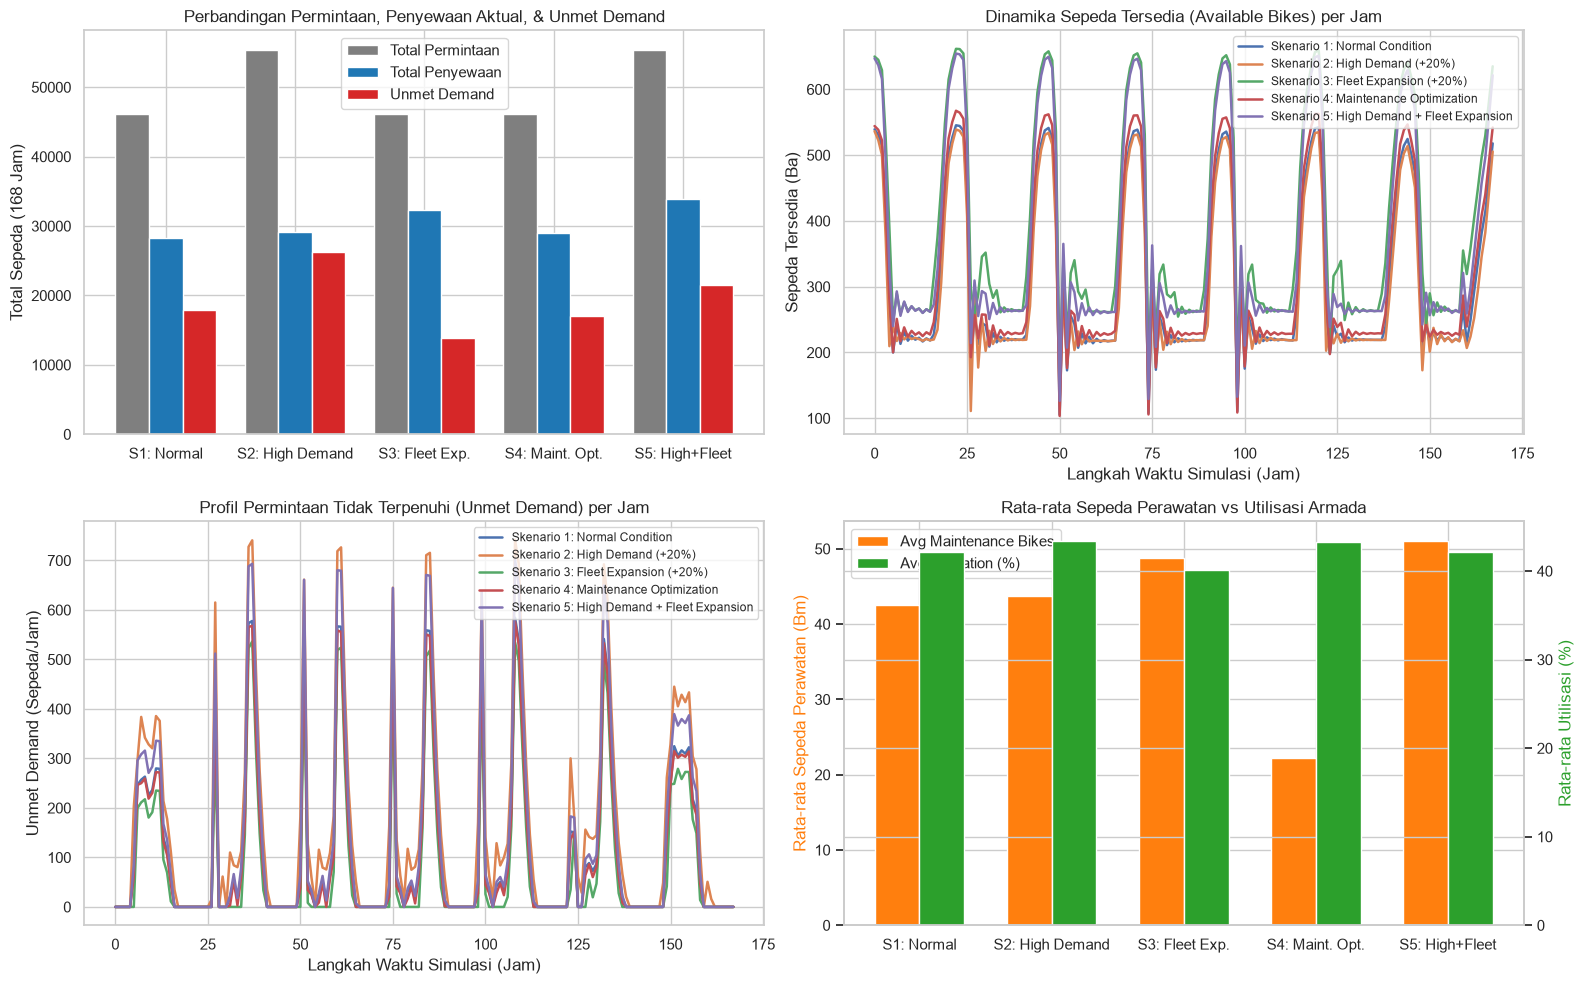

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Panel 1: Total Permintaan vs Total Penyewaan vs Unmet Demand
x = np.arange(len(comparison_df))
w = 0.26
axes[0, 0].bar(x - w, comparison_df['Total_Demand'], width=w, label='Total Permintaan', color='#7f7f7f')
axes[0, 0].bar(x, comparison_df['Total_Rentals'], width=w, label='Total Penyewaan', color='#1f77b4')
axes[0, 0].bar(x + w, comparison_df['Total_Unmet_Demand'], width=w, label='Unmet Demand', color='#d62728')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(['S1: Normal', 'S2: High Demand', 'S3: Fleet Exp.', 'S4: Maint. Opt.', 'S5: High+Fleet'])
axes[0, 0].set_title('Perbandingan Permintaan, Penyewaan Aktual, & Unmet Demand')
axes[0, 0].set_ylabel('Total Sepeda (168 Jam)')
axes[0, 0].legend()

# Panel 2: Dinamika Available Bikes (Ba) Antar Skenario
for sc_name, grp in all_ts_df.groupby('scenario_name', sort=False):
    axes[0, 1].plot(grp['step'], grp['available_bikes'], lw=1.8, label=sc_name)
axes[0, 1].set_title('Dinamika Sepeda Tersedia (Available Bikes) per Jam')
axes[0, 1].set_xlabel('Langkah Waktu Simulasi (Jam)')
axes[0, 1].set_ylabel('Sepeda Tersedia (Ba)')
axes[0, 1].legend(fontsize=8.5)

# Panel 3: Dinamika Unmet Demand Antar Skenario
for sc_name, grp in all_ts_df.groupby('scenario_name', sort=False):
    axes[1, 0].plot(grp['step'], grp['unmet_demand'], lw=1.8, label=sc_name)
axes[1, 0].set_title('Profil Permintaan Tidak Terpenuhi (Unmet Demand) per Jam')
axes[1, 0].set_xlabel('Langkah Waktu Simulasi (Jam)')
axes[1, 0].set_ylabel('Unmet Demand (Sepeda/Jam)')
axes[1, 0].legend(fontsize=8.5)

# Panel 4: Rata-rata Sepeda dalam Perawatan & Utilisasi Armada
ax4 = axes[1, 1]
ax4_twin = ax4.twinx()
b1 = ax4.bar(x - 0.17, comparison_df['Avg_Maintenance_Bikes'], width=0.34, color='#ff7f0e', label='Avg Maintenance Bikes')
b2 = ax4_twin.bar(x + 0.17, comparison_df['Avg_Utilization_Pct'], width=0.34, color='#2ca02c', label='Avg Utilization (%)')
ax4.set_xticks(x)
ax4.set_xticklabels(['S1: Normal', 'S2: High Demand', 'S3: Fleet Exp.', 'S4: Maint. Opt.', 'S5: High+Fleet'])
ax4.set_title('Rata-rata Sepeda Perawatan vs Utilisasi Armada')
ax4.set_ylabel('Rata-rata Sepeda Perawatan (Bm)', color='#ff7f0e')
ax4_twin.set_ylabel('Rata-rata Utilisasi (%)', color='#2ca02c')
ax4.legend([b1, b2], ['Avg Maintenance Bikes', 'Avg Utilization (%)'], loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_scenario_comparison.png', dpi=150)
plt.show()

## 4. Penentuan Skenario Terbaik Berdasarkan Indikator Kinerja
Untuk menentukan skenario kebijakan terbaik secara objektif, digunakan **Indeks Kinerja Kebijakan Komposit (Composite Policy Effectiveness Score, 0–100)** berdasarkan tiga indikator utama:
1. **Service Level / Tingkat Pemenuhan Permintaan (Bobot 50%):** $\frac{\text{Total Penyewaan}}{\text{Total Permintaan}} \times 100\%$ — mengukur efektivitas pemenuhan kebutuhan pengguna.
2. **Efisiensi Ketersediaan & Pencegahan Bottleneck Perawatan (Bobot 25%):** Mengukur rendahnya antrean sepeda rusak ($100 - \frac{\text{Avg Maintenance Bikes}}{\text{Total Fleet}} \times 100\%$).
3. **Efisiensi Utilisasi Armada / CAPEX Efficiency (Bobot 25%):** Mengukur produktivitas aset armada ($\frac{\text{Total Penyewaan}}{\text{Total Fleet}} \times \text{faktor normalisasi}$) agar peningkatan *Service Level* tidak semata-mata dicapai dengan menumpuk armada menganggur berbiaya tinggi.

In [6]:
eval_df = comparison_df.copy()

# Komponen 1: Service Level (%)
eval_df['Score_Service_Level'] = eval_df['Service_Level_Pct']

# Komponen 2: Kesehatan Armada (bebas antrean perawatan)
fleet_sizes = eval_df['parameters'].apply(lambda p: p['total_fleet'])
eval_df['Score_Fleet_Health'] = (1.0 - (eval_df['Avg_Maintenance_Bikes'] / fleet_sizes)) * 100.0

# Komponen 3: Produktivitas Per Unit Armada (Total Rentals per Fleet Unit dinormalisasi terhadap nilai tertinggi)
rentals_per_bike = eval_df['Total_Rentals'] / fleet_sizes
eval_df['Score_Asset_Productivity'] = (rentals_per_bike / rentals_per_bike.max()) * 100.0

# Skor Komposit Terbobot
eval_df['Composite_Score'] = (
    0.50 * eval_df['Score_Service_Level'] +
    0.25 * eval_df['Score_Fleet_Health'] +
    0.25 * eval_df['Score_Asset_Productivity']
).round(2)

ranked_df = eval_df.sort_values(by=['Composite_Score', 'Service_Level_Pct'], ascending=[False, False]).reset_index(drop=True)
ranked_df.insert(0, 'Rank', range(1, len(ranked_df) + 1))

display(ranked_df[[
    'Rank', 'scenario_name', 'Service_Level_Pct', 'Total_Unmet_Demand',
    'Avg_Available_Bikes', 'Avg_Utilization_Pct', 'Avg_Maintenance_Bikes', 'Composite_Score'
]])

best_scenario = ranked_df.iloc[0]
print('=== REKOMENDASI SKENARIO TERBAIK ===')
print(f'Skenario Terpilih       : {best_scenario["scenario_name"]}')
print(f'Composite Score         : {best_scenario["Composite_Score"]} / 100')
print(f'Service Level           : {best_scenario["Service_Level_Pct"]}%')
print(f'Total Unmet Demand      : {best_scenario["Total_Unmet_Demand"]} sepeda')
print(f'Avg Available Bikes     : {best_scenario["Avg_Available_Bikes"]} sepeda')
print(f'Avg Utilization         : {best_scenario["Avg_Utilization_Pct"]}%')
print(f'Avg Maintenance Bikes   : {best_scenario["Avg_Maintenance_Bikes"]} sepeda')

,Rank,scenario_name,Service_Level_Pct,Total_Unmet_Demand,Avg_Available_Bikes,Avg_Utilization_Pct,Avg_Maintenance_Bikes,Composite_Score
0,1,Skenario 3: Fleet Expansion (+20%),69.97,13865.24,382.74,40.08,48.72,81.36
1,2,Skenario 4: Maintenance Optimization,62.95,17107.13,318.27,43.26,22.17,80.45
2,3,Skenario 1: Normal Condition,61.29,17872.62,304.70,42.12,42.57,78.12
3,4,Skenario 5: High Demand + Fleet Expansion,61.29,21447.14,365.65,42.12,51.08,78.12
4,5,Skenario 2: High Demand (+20%),52.67,26225.47,295.62,43.43,43.80,74.51


=== REKOMENDASI SKENARIO TERBAIK ===
Skenario Terpilih       : Skenario 3: Fleet Expansion (+20%)
Composite Score         : 81.36 / 100
Service Level           : 69.97%
Total Unmet Demand      : 13865.24 sepeda
Avg Available Bikes     : 382.74 sepeda
Avg Utilization         : 40.08%
Avg Maintenance Bikes   : 48.72 sepeda


## 5. Penyimpanan Hasil Eksperimen Skenario untuk Aplikasi Web Flask

In [7]:
summary_csv_path = ARTIFACTS_DIR / 'scenario_comparison_summary.csv'
ts_csv_path = ARTIFACTS_DIR / 'scenario_timeseries.csv'
json_out_path = ARTIFACTS_DIR / 'scenario_experiments.json'

ranked_export = ranked_df.drop(columns=['parameters'])
ranked_export.to_csv(summary_csv_path, index=False)
all_ts_df.to_csv(ts_csv_path, index=False)

scenario_payload = {
    'generated_at': datetime.now().isoformat(timespec='seconds'),
    'horizon_hours': int(len(sim_input_df)),
    'best_scenario': {
        'scenario_id': str(best_scenario['scenario_id']),
        'scenario_name': str(best_scenario['scenario_name']),
        'composite_score': float(best_scenario['Composite_Score']),
        'service_level_pct': float(best_scenario['Service_Level_Pct']),
        'total_unmet_demand': float(best_scenario['Total_Unmet_Demand']),
        'rationale': (
            f"{best_scenario['scenario_name']} meraih skor kinerja tertinggi ({best_scenario['Composite_Score']}/100) "
            f"dengan tingkat pemenuhan permintaan (Service Level) sebesar {best_scenario['Service_Level_Pct']}% "
            f"dan menjaga keseimbangan antara ketersediaan armada serta produktivitas aset."
        )
    },
    'scenarios': comparison_df.to_dict(orient='records'),
    'ranking': ranked_export.to_dict(orient='records')
}

with open(json_out_path, 'w', encoding='utf-8') as f:
    json.dump(scenario_payload, f, indent=2)

print('=== ARTEFAK EKSPERIMEN SKENARIO TERSIMPAN ===')
print(f'1. JSON Skenario : {json_out_path}')
print(f'2. Ringkasan CSV : {summary_csv_path}')
print(f'3. Time-Series   : {ts_csv_path}')
# Simpan juga scenario_results.json untuk kompatibilitas suite Colab
with open(ARTIFACTS_DIR / 'scenario_results.json', 'w', encoding='utf-8') as f:
    json.dump(scenario_payload, f, indent=2)
print('Hasil skenario juga disimpan di artifacts/scenario_results.json')


=== ARTEFAK EKSPERIMEN SKENARIO TERSIMPAN ===
1. JSON Skenario : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\scenario_experiments.json
2. Ringkasan CSV : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\scenario_comparison_summary.csv
3. Time-Series   : C:\Users\HS\Desktop\UTS MOSI (TEORI DAN PRAK) - PEMODELAN DAN SIMULASI\bike-dynamics\artifacts\scenario_timeseries.csv
Hasil skenario juga disimpan di artifacts/scenario_results.json
